In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [7]:
df = pd.read_csv("emails.csv")

print(df.head())
print(df.info())
print(df.isnull().sum())
print(df.columns)

  Email No.  the  to  ect  and  for  of    a  you  hou  ...  connevey  jay  \
0   Email 1    0   0    1    0    0   0    2    0    0  ...         0    0   
1   Email 2    8  13   24    6    6   2  102    1   27  ...         0    0   
2   Email 3    0   0    1    0    0   0    8    0    0  ...         0    0   
3   Email 4    0   5   22    0    5   1   51    2   10  ...         0    0   
4   Email 5    7   6   17    1    5   2   57    0    9  ...         0    0   

   valued  lay  infrastructure  military  allowing  ff  dry  Prediction  
0       0    0               0         0         0   0    0           0  
1       0    0               0         0         0   1    0           0  
2       0    0               0         0         0   0    0           0  
3       0    0               0         0         0   0    0           0  
4       0    0               0         0         0   1    0           0  

[5 rows x 3002 columns]
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5172 entries

In [8]:
df.dropna(inplace=True)
df.drop_duplicates(inplace=True)

print("Dataset Shape:", df.shape)

Dataset Shape: (5172, 3002)


In [9]:
# Remove email identification column
df.drop('Email No.', axis=1, inplace=True)

# Separate input and output
X = df.drop('Prediction', axis=1)
y = df['Prediction']

print("Features:", X.shape)
print("Target:", y.shape)

print("\nClass Distribution:")
print(y.value_counts())

Features: (5172, 3000)
Target: (5172,)

Class Distribution:
Prediction
0    3672
1    1500
Name: count, dtype: int64


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (4137, 3000)
Testing Data: (1035, 3000)


In [11]:
from sklearn.preprocessing import MaxAbsScaler

scaler = MaxAbsScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [12]:
knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train, y_train)

knn_pred = knn.predict(X_test)

print("KNN Accuracy:", accuracy_score(y_test, knn_pred))
print(classification_report(y_test, knn_pred))

KNN Accuracy: 0.8676328502415459
              precision    recall  f1-score   support

           0       0.97      0.84      0.90       735
           1       0.70      0.94      0.81       300

    accuracy                           0.87      1035
   macro avg       0.84      0.89      0.85      1035
weighted avg       0.89      0.87      0.87      1035



In [13]:
svm = LinearSVC(random_state=42, max_iter=5000)

svm.fit(X_train, y_train)

svm_pred = svm.predict(X_test)

print("SVM Accuracy:", accuracy_score(y_test, svm_pred))
print(classification_report(y_test, svm_pred))

SVM Accuracy: 0.9719806763285024
              precision    recall  f1-score   support

           0       0.99      0.97      0.98       735
           1       0.93      0.97      0.95       300

    accuracy                           0.97      1035
   macro avg       0.96      0.97      0.97      1035
weighted avg       0.97      0.97      0.97      1035



In [14]:
results = pd.DataFrame({
    'Model': ['KNN', 'SVM'],
    'Accuracy': [
        accuracy_score(y_test, knn_pred),
        accuracy_score(y_test, svm_pred)
    ],
    'Precision': [
        precision_score(y_test, knn_pred),
        precision_score(y_test, svm_pred)
    ],
    'Recall': [
        recall_score(y_test, knn_pred),
        recall_score(y_test, svm_pred)
    ],
    'F1 Score': [
        f1_score(y_test, knn_pred),
        f1_score(y_test, svm_pred)
    ]
})

print(results)

  Model  Accuracy  Precision    Recall  F1 Score
0   KNN  0.867633   0.702233  0.943333  0.805121
1   SVM  0.971981   0.932907  0.973333  0.952692


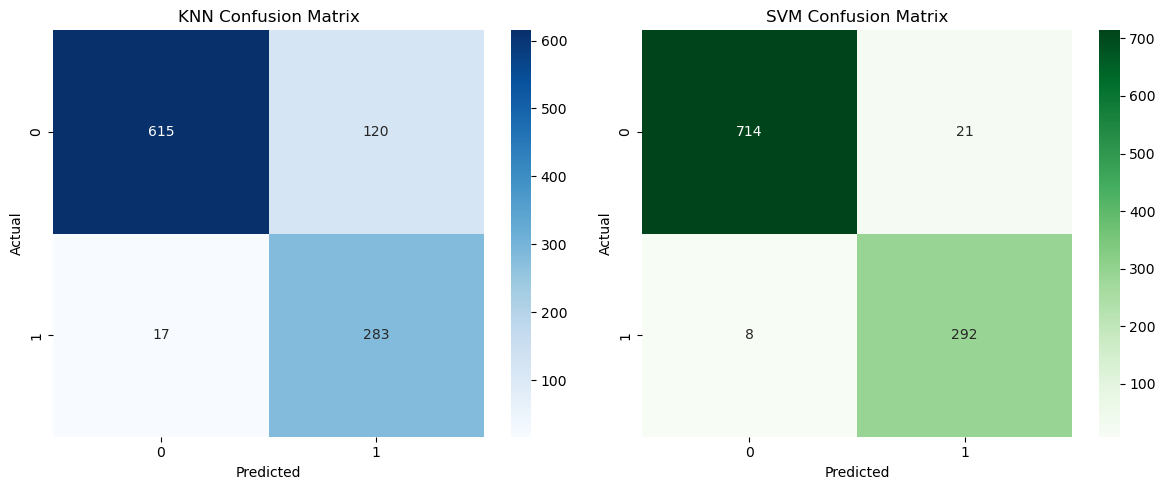

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(
    confusion_matrix(y_test, knn_pred),
    annot=True, fmt='d', cmap='Blues', ax=axes[0]
)
axes[0].set_title("KNN Confusion Matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(
    confusion_matrix(y_test, svm_pred),
    annot=True, fmt='d', cmap='Greens', ax=axes[1]
)
axes[1].set_title("SVM Confusion Matrix")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

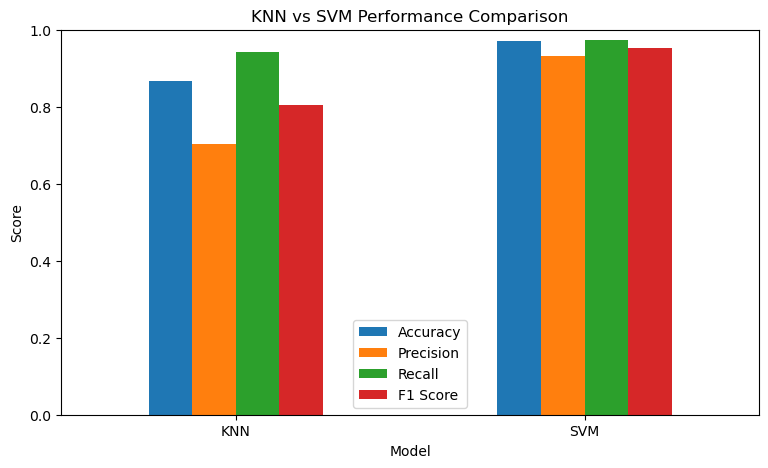

In [16]:
results.set_index('Model').plot(
    kind='bar', figsize=(9, 5)
)

plt.title("KNN vs SVM Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.show()